In [5]:
Ce
ds
mixed layer depth



In [2]:
# modules 

import importlib
import buoyancy_gradient
importlib.reload(buoyancy_gradient)   # force reload
from buoyancy_gradient import buo_coarse
import numpy as np 
import xarray as xr 
import read_mitgcm 
import coarsen_UVWTS 
import build_coarse_grid 
import make_grid
import gsw

from MITgcmutils import mds 
import mld_avg

# ---------------------------- parameters -------------------------------------
t = 4945536
box_i = box_j = 10 
# ---------------------------- MITgcm Path ------------------------------------- 
path_scratch = '/scratch/jczhang/' 
path_MITgcm = 'MITgcm_5km/MITgcm/verification/tutorial_reentrant_channel/run/' 
path_ds = 'data_5km/var_6000/' 
grid_dir = path_scratch + path_MITgcm 
# ---------------------------- grid ------------------------------------- 
ds_fine = read_mitgcm.read_mitgrid_staggered(grid_dir) 
ds_coarse = build_coarse_grid.build_coarse_grid_staggered(ds_fine,box_j=box_j, box_i=box_i) 
grid = make_grid.make_grid_periodic_x(ds_coarse) 
# ---------------------------- Ce, ds ------------------------------------- 
# efficiency coefficient Ce 
C_e = 0.03 
# hard upper cap - useless for my case, since dx < 111 km 
submeso_Lmax = 111000 # m 
# delta_s: local coarse model gridscale dimension 
delta_sx = ds_coarse["DXC"].clip(max=submeso_Lmax) # (j, i_g) 
delta_sy = ds_coarse["DYC"].clip(max=submeso_Lmax) # (j_g, i) 
# ---------------------------- mixed layer depth ------------------------------------ 
# mixed layer depth 
diagMXL = mds.rdmds(path_scratch + path_MITgcm + 'Diags/' +'DiagMXL_2d', t) 
kpphbl = xr.DataArray(diagMXL[1, :,:], dims = ("j","i"), name = "kpphbl") 
kpphbl_coarse = coarsen_UVWTS.coarse_field("kpphbl", kpphbl, ds_fine, box_j, box_i) 
mixLayerU = grid.interp(kpphbl_coarse, 'X', to='left') # (j, i_g) 
mixLayerV = grid.interp(kpphbl_coarse, 'Y', to='left') # (j_g, i) 

# ---------------------------- buoyancy gradient and buoyancy ------------------------------------- 
T = read_mitgcm._ocean_var(grid_dir, "T", t, ("k","j","i")) 
T_coarse = coarsen_UVWTS.coarse_field("T", T, ds_fine, box_j, box_i) 
S = read_mitgcm._ocean_var(grid_dir, "S", t, ("k","j","i")) 
S_coarse = coarsen_UVWTS.coarse_field("S", S, ds_fine, box_j, box_i) 
Eta = read_mitgcm._ocean_var(grid_dir, "Eta", t, ("j","i")) 
Eta_coarse = coarsen_UVWTS.coarse_field("Eta", Eta, ds_fine, box_j, box_i) 
ds_ocean = xr.Dataset(dict(T=T, S=S, Eta=Eta)) 
ds_ocean_c = xr.Dataset(dict(T=T_coarse, S=S_coarse, Eta=Eta_coarse)) 
b, b_grad, dBdx_u, dBdy_v = buo_coarse(ds_coarse, ds_ocean_c, "fill") 

# ---------------------------- buoyancy gradient integral -------------------------------------------
RF = ds_coarse["RF"]
DRF = ds_coarse["DRF"]
# top interface:
rF_top = RF.isel(k_p1=slice(0, -1)).rename({"k_p1": "k"})
# ---------------------------- buoyancy gradient integral -------------------------------------------
RF = ds_coarse["RF"]
DRF = ds_coarse["DRF"]
# top interface:
rF_top = RF.isel(k_p1=slice(0, -1)).rename({"k_p1": "k"})
print(rF_top.shape)
# match the dimensions
rF_U = rF_top.broadcast_like(dBdx_u) # (k, j, i_g)
rF_V = rF_top.broadcast_like(dBdy_v) # (k, j_g, i)
drF_U = DRF.rename({"k": "k"}).broadcast_like(dBdx_u)
drF_V = DRF.rename({"k": "k"}).broadcast_like(dBdy_v)
mixLayerU_3D = mixLayerU.broadcast_like(dBdx_u)
mixLayerV_3D = mixLayerV.broadcast_like(dBdy_v)
# dzLoc_U = MAX(0, MIN(drF(k), mixLayerU + rF(k)))
dz_U = xr.where(
    mixLayerU_3D + rF_U > 0.0,
    xr.apply_ufunc(np.minimum, drF_U, mixLayerU_3D + rF_U),
    0.0
)
# dzLoc_V = MAX(0, MIN(drF(k), mixLayerV + rF(k)))
dz_V = xr.where(
    mixLayerV_3D + rF_V > 0.0,
    xr.apply_ufunc(np.minimum, drF_V, mixLayerV_3D + rF_V),
    0.0
)
# integrate over mixed layer
dBuoyX_Hu_int = (dBdx_u * dz_U).sum("k")
dBuoyY_Hv_int = (dBdy_v * dz_V).sum("k")
dBuoyX_Hu_int.name = "dBuoyX_Hu"
dBuoyY_Hv_int.name = "dBuoyY_Hv"
# ---------------------------- coriolis and tau------------------------------------- 
f0 = -1.363e-4 # s^-1 
beta = 1.313e-11 # s^-1 m^-1 
subMeso_invTau = 1.6e-6 
YC_da = xr.DataArray(ds_coarse["YC"], dims=('j','i')) 
y_ref = float(YC_da.mean()) 
f = (f0 + beta*(YC_da - y_ref)) # (j,i), s^-1 
f_eff = np.hypot(f, subMeso_invTau) 
f_U = grid.interp(f_eff, 'X', to='left') # (j,i_g) 
f_V = grid.interp(f_eff, 'Y', to='left') # (j_g,i) 

(49,)


In [19]:
# ---------------------------- Lf = max(M/f, NH/|f|, Lf_min)------------------------------------- 
# 1.  M^2 H at the center
# intepolate buoyancy gradient to the cell center
dBuoyX_C = grid.interp(dBuoyX_Hu_int, 'X')
dBuoyY_C = grid.interp(dBuoyY_Hv_int, 'Y')
MsquareH = xr.apply_ufunc(np.hypot, dBuoyX_C, dBuoyY_C)
MsquareH = MsquareH.rename("MsquareH")
MsquareH.attrs.update(long_name="|∫_ML ∇_H b| at centers", units="m s^-2")

# 2. NHmixLay
RF   = ds_coarse["RF"]      # (k_p1), negative downward
DRF  = ds_coarse["DRF"]     # (k)
hFacC = ds_coarse["hFacC"]  # (k,j,i)
# effective mixed layer depth
Hcol = (-RF).isel(k_p1=-1)        
H_eff = xr.where(np.isfinite(kpphbl_coarse), kpphbl_coarse.clip(min=0.0), 0.0)
H_eff = H_eff.clip(max=Hcol)
# 
K = b.sizes['k']
k_idx = b['k'] if 'k' in b.coords else np.arange(K)

# 1) layer bounds as data-only 1D arrays, then give them b's k-index
z_top_1d = xr.DataArray(
    -RF.isel(k_p1=slice(0, -1)).data,  
    dims=('k',),
    coords={'k': k_idx},
)
z_bot_1d = xr.DataArray(
    -RF.isel(k_p1=slice(1, None)).data,
    dims=('k',),
    coords={'k': k_idx},
)

# 2) broadcast to (k,j,i) with the same coords as b
z_top = z_top_1d.broadcast_like(b)   # (k,j,i)
z_bot = z_bot_1d.broadcast_like(b)   # (k,j,i)

# 3) thickness
thk = (z_bot - z_top) * hFacC

# --- overlap thickness w(k,j,i) of each layer with 0..H_eff ---
H3 = H_eff.broadcast_like(b)        # (k,j,i)
minH_zbot = xr.apply_ufunc(np.minimum, H3, z_bot)
w  = (minH_zbot - z_top).clip(min=0.0)
w  = xr.where(w > thk, thk, w)      # cannot exceed actual layer thickness
# --- vertical derivative of buoyancy:
#   dbdz_up  ≈ (b(k) - b(k+1)) / Δz  > 0
DRF_3d = DRF.rename({"k": "k"}).broadcast_like(b)
db = b - b.shift(k=-1)              # b(k) - b(k+1)
dbdz_up = (db / DRF_3d).where(DRF_3d > 0)   # (k,j,i), s^-2; last level NaN

# keep only stable part (like MAX(-sigmaR,0) in MITgcm)
N2_stable = dbdz_up.clip(min=0.0)

# --- integrate N^2 over the mixed layer with thickness weights ---
# S(j,i) ~ ∫_ML N^2 dz
S = (N2_stable * w).sum("k")        # (j,i), units s^-2 * m

# NHmixLay^2 = H * S  -> units m^2 s^-2
NHmixLay = np.sqrt(S * H_eff)
NHmixLay = NHmixLay.where(H_eff > 0.0)

NHmixLay.name = "NHmixLay"
NHmixLay.attrs.update(
    long_name="H * N (mixed-layer stratification/velocity scale)",
    units="m s^-1",
)
#  Lf
cand1 = MsquareH / (f_eff ** 2)   # [m]  ~ M^2 / f^2
cand2 = NHmixLay / f_eff         # [m]  ~ (H N) / f
LfMin = 1000
Lf = xr.apply_ufunc(np.maximum, cand1, cand2)
Lf = xr.where(Lf < LfMin, LfMin, Lf)
Lf = Lf.rename("Lf")
Lf.attrs.update(long_name="Fox–Kemper MEI frontal length scale", units="m")
Lf_U = grid.interp(Lf, 'X', to='left') # (j, i_g) 
Lf_V = grid.interp(Lf, 'Y', to='left') # (j_g, i) 

In [20]:
# ---------------------------- vertical structure ------------------------------------- 
# RF is negative downward (k_p1 interfaces); use it directly. 
rF_U = rF_top.broadcast_like(dBdx_u) # (k,j,i_g) 
rF_V = rF_top.broadcast_like(dBdy_v) # (k,j_g,i)  
# z2H must be negative inside the ML: [-2, 0] 
z2H_U = xr.where(mixLayerU > 0, 2.0 * rF_U / mixLayerU_3D, 0.0) 
z2H_V = xr.where(mixLayerV > 0, 2.0 * rF_V / mixLayerV_3D, 0.0) 
# enforce canonical dim order
z2H_U = z2H_U.transpose("k", "j", "i_g")
z2H_V = z2H_V.transpose("k", "j_g", "i")
def mu_from(z2H): 
    q = (1.0 + z2H)**2 
    mu = (1.0 - q) * (1.0 + (5.0/21.0)*q) 
    return xr.where(mu > 0.0, mu, 0.0) 
muU = mu_from(z2H_U) # (k,j,i_g) 
muV = mu_from(z2H_V) # (k,j_g,i) 

In [29]:
# ---------------------------- stream function ------------------------------------- 
dBuoyY_Hu_int = grid.interp(grid.interp(dBuoyY_Hv_int, 'Y', to='center'), 'X', to='left')                 
dBuoyX_Hv_int = grid.interp(grid.interp(dBuoyX_Hu_int, 'Y', to='left'), 'X', to='center') 
PsiU0 = (-C_e * dBuoyX_Hu_int * mixLayerU * delta_sx * (1.0 / Lf_U) * (1.0 / f_U)).fillna(0.0) # (j,i_g) 
PsiV0 = (-C_e * dBuoyY_Hv_int * mixLayerV * delta_sy * (1.0 / Lf_V) * (1.0 / f_V)).fillna(0.0) # (j_g,i) 
# PsiU0 = (-C_e * dBuoyY_Hu_int * mixLayerU * delta_sx * (1.0 / Lf_U) * (1.0 / f_U)).fillna(0.0) # (j,i_g) 
# PsiV0 = (-C_e * (dBuoyX_Hv_int) * mixLayerV * delta_sy * (1.0 / Lf_V) * (1.0 / f_V)).fillna(0.0) # (j_g,i) 
PsiU0.name, PsiV0.name = "PsiU0", "PsiV0"
PsiU0.attrs.update(long_name="MEI streamfunction amplitude at U-faces", units="m^2 s^-1")
PsiV0.attrs.update(long_name="MEI streamfunction amplitude at V-faces", units="m^2 s^-1")

# ---------------------------- 3D streamfunction ΨX, ΨY ------------------------
# Broadcast Ψ0 to 3D and multiply by vertical shape μ(z/H)
PsiX = PsiU0.broadcast_like(muU) * muU   # (k, j, i_g)
PsiY = PsiV0.broadcast_like(muV) * muV   # (k, j_g, i)

PsiX.name = "PsiX_submeso"
PsiY.name = "PsiY_submeso"
PsiX.attrs.update(long_name="MEI bolus streamfunction (x-component)", units="m^2 s^-1")
PsiY.attrs.update(long_name="MEI bolus streamfunction (y-component)", units="m^2 s^-1")

In [27]:
# --- grads of mean T on C, then to W (k,j,i) ---
wetU = ds_coarse["hFacW"] > 0
wetV = ds_coarse["hFacS"] > 0

dTdx_U = (grid.diff(T_coarse, 'X') / ds_coarse["DXC"]).where(wetU)      # (k,j,i_g)
dTdy_V = (grid.diff(T_coarse, 'Y', boundary='fill') / ds_coarse["DYC"]).where(wetV)  # (k,j_g,i)

# bring face-grads to centers
dTdx_C = grid.interp(dTdx_U.fillna(0.0), 'X')    # (k,j,i)
dTdy_C = grid.interp(dTdy_V.fillna(0.0), 'Y')    # (k,j,i)

# average C→W so vertical index matches Ψ(k,·,·) at W levels
dTdx_W = 0.5*(dTdx_C + dTdx_C.shift(k=1))
dTdy_W = 0.5*(dTdy_C + dTdy_C.shift(k=1))

# --- bring Ψ components to centers (same W levels) ---
PsiX_C = grid.interp(PsiX, 'X')    # (k,j,i)
PsiY_C = grid.interp(PsiY, 'Y')    # (k,j,i)

# --- vertical eddy temp flux from cross product ----------------------------
Fz_T_cross = (PsiX_C * dTdy_W - PsiY_C * dTdx_W).rename("Fz_T_cross")   # (k,j,i)
Fz_T_cross.attrs.update(long_name="(Ψ × ∇T)_z", units="K m s^-1")

# (optional) convert to heat units
rho0, cp = 1035.0, 3990.0
Qz_T_cross = (rho0 * cp) * Fz_T_cross
Qz_T_cross.name = "Qz_T_cross"
Qz_T_cross.attrs.update(units="W m^-2")
submeso_wT_FK = mld_avg.mld_avg(Qz_T_cross, kpphbl_coarse, ds_coarse)


In [38]:
print(Lf_U)

<xarray.DataArray 'Lf' (j: 120, i_g: 60)> Size: 58kB
array([[          nan,           nan,           nan, ...,           nan,
                  nan,           nan],
       [1000.        , 1000.        , 1000.        , ..., 1000.        ,
        1000.        , 1000.        ],
       [1000.        , 1000.        , 1000.        , ..., 1000.        ,
        1000.        , 1000.        ],
       ...,
       [2924.78354929, 3053.1104909 , 3112.63878107, ..., 3631.31810465,
        3252.99339818, 3040.80975197],
       [2694.80421057, 2898.63169099, 2992.47422393, ..., 3418.0834009 ,
        3119.88311911, 2721.65544264],
       [3195.46258116, 2928.69076958, 2958.07100749, ..., 3126.94150298,
        2832.11140375, 2998.03100249]])
Coordinates:
  * j        (j) int64 960B 0 1 2 3 4 5 6 7 ... 112 113 114 115 116 117 118 119
  * i_g      (i_g) int64 480B 0 1 2 3 4 5 6 7 8 9 ... 51 52 53 54 55 56 57 58 59


Total data number is: 4841


Text(0.5, 0.98, 'submesoscale heat flux (t=[3900096 3900312 3900528 ... 4945104 4945320 4945536]) — fine vs coarse')

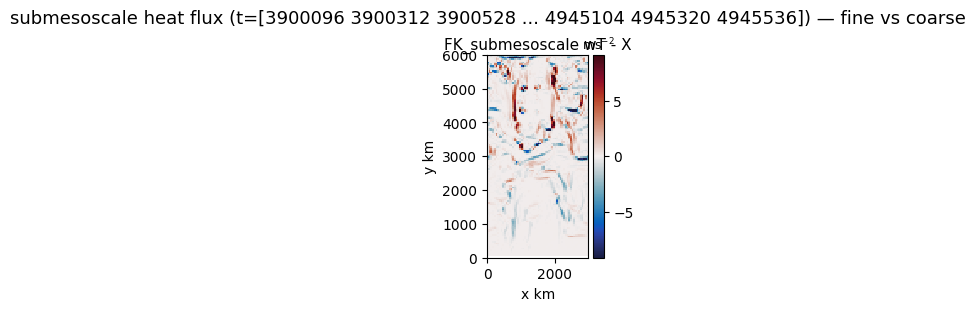

In [32]:
import sys
from pathlib import Path
sys.path.append(str(Path.cwd().parent))
import coarsen_UVWTS
import read_mitgcm
import build_coarse_grid
import numpy as np
from matplotlib import pyplot as plt
import cmocean.cm as cmo
from matplotlib.colors import TwoSlopeNorm
from matplotlib.colors import Normalize

import wT
import xarray as xr
from MITgcmutils import mds
import mld_avg
import importlib
importlib.reload(wT)   # force reload
importlib.reload(read_mitgcm) 
importlib.reload(build_coarse_grid) 
#  MITgcm path
path_scratch = '/scratch/jczhang/'
path_MITgcm = 'MITgcm_5km/MITgcm/verification/tutorial_reentrant_channel/run/'
grid_dir = path_scratch + path_MITgcm
# time index
nStep1, nStep2, dS = 3900096, 4945536, 216
time_index = np.arange(nStep1, nStep2 + 1, dS, dtype=int)
num_data = time_index.size
print("Total data number is:", num_data)
# choose a vertical level
k = 0
box_i, box_j=10, 10
# get the grid variables and create the ds
ds_fine = read_mitgcm.read_mitgrid_staggered(grid_dir)
ds_coarse = build_coarse_grid.build_coarse_grid_staggered(ds_fine,box_j=box_j, box_i=box_i)

# coordinate variable
XC = ds_fine["XC"].values
YC = ds_fine["YC"].values
XCc = ds_coarse["XC"].values
YCc = ds_coarse["YC"].values

# limits function
def sym_limits(Z, q = 0.995):
    v = np.nanquantile(np.abs(Z), q)
    return float(v)

def pos_limits(Z, q=0.995):
    v = np.nanquantile(Z, q)
    return float(v)

# load the data
# submeso_wT_npy = np.load("./var/submeso_wT.npy")
# print(submeso_wT_npy.shape)

# W = read_mitgcm._ocean_var(grid_dir, "W", time_index[-1], ("k_l","j","i"))
# W_coarse = coarsen_UVWTS.coarse_field("W", W, ds_fine, box_j, box_i)
# T = read_mitgcm._ocean_var(grid_dir, "T", time_index[-1], ("k","j","i"))
# T_coarse = coarsen_UVWTS.coarse_field("T", T, ds_fine, box_j, box_i)

# ds_ocean = xr.Dataset(dict(W=W, T=T))
# ds_ocean_c = xr.Dataset(dict(W=W_coarse, T=T_coarse))

# submeso_wT_coarse = wT.submeso_vertical_heat_flux(ds_fine, ds_coarse, ds_ocean, ds_ocean_c, box_j = 10, box_i = 10,boundary_Z = "fill", to_wm2 = True)

# #  mixed layer avergae
# diagMXL = mds.rdmds(path_scratch + path_MITgcm + 'Diags/' +'DiagMXL_2d', time_index[-1])
# kpphbl = xr.DataArray(diagMXL[1, :,:], dims = ("j","i"), name = "kpphbl")
# kpphbl_coarse = coarsen_UVWTS.coarse_field("kpphbl", kpphbl, ds_fine, box_j, box_i)
# submeso_wT_coarse_mld = mld_avg.mld_avg(submeso_wT_coarse, kpphbl_coarse, ds_coarse)

# div_coarse_mld[2403 + _ ,:,:]
fields = {
    "FK_submesoscale wT - X":  {"Z": submeso_wT_FK[:,:],         "units": r"ms$^{-2}$",    "kind": "signed", "cmap": cmo.balance, "X": XCc/1e3, "Y": YCc/1e3 },
    # "submeso_wT coarse":  {"Z": submeso_wT_coarse[k,:,:],    "units": r"m s$^{-1}$",    "kind": "signed", "cmap": cmo.balance, "X": XCc[:,:]/1e3, "Y": YCc[:,:]/1e3},
    # "submeso_wT coarse mld":  {"Z": submeso_wT_coarse_mld[:,:],  "units": r"m s$^{-1}$", "kind": "signed", "cmap": cmo.balance, "X": XCc/1e3, "Y": YCc/1e3},
    # "submeso_wT coarse mld Fox Kemper":  {"Z": submeso_wT_FK[:,:],  "units": r"m s$^{-1}$", "kind": "signed", "cmap": cmo.balance, "X": XCc/1e3, "Y": YCc/1e3},

}

# Compute norms/limits per field
for key, meta in fields.items():    # key is the variable name, meta is the dict contains the variables, units...
    Z = meta["Z"]
    if meta["kind"] == "signed":
        q = sym_limits(Z)
        meta["norm"] = TwoSlopeNorm(vcenter=0.0, vmin=-q, vmax=+q)
    elif meta["kind"] == "positive":
        q = pos_limits(Z)
        meta["norm"] = Normalize(vmin=0.0, vmax=q)
    elif meta["kind"] == "seq":
        meta["norm"] = Normalize(vmin=np.nanmin(Z), vmax=np.nanmax(Z))
    else:
        meta["norm"] = None

# Plot: 2×5
fig, axes = plt.subplots(1, 1, figsize=(3, 3), constrained_layout=True, squeeze=False)
axes = axes.ravel()

for ax, (title, meta) in zip(axes, fields.items()):
    X = meta["X"]; Y = meta["Y"]; Z = meta["Z"]; 
    cmap = meta["cmap"]
    norm = meta["norm"]
    pc = ax.pcolormesh(X, Y, Z, shading='auto', cmap=cmap, norm=norm)
    ax.set_aspect('equal', adjustable='box')
    ax.set_title(title, fontsize=11, pad=4)
    ax.set_xlabel('x km'); ax.set_ylabel('y km')
    cb = fig.colorbar(pc, ax=ax, pad=0.02)
    cb.ax.set_title(meta["units"], pad=4, fontsize=9)

fig.suptitle(f"submesoscale heat flux (t={time_index}) — fine vs coarse", fontsize=13)


# Plot

Total data number is: 4841


Text(0.5, 0.98, 'submesoscale heat flux (t=[3900096 3900312 3900528 ... 4945104 4945320 4945536]) — fine vs coarse')

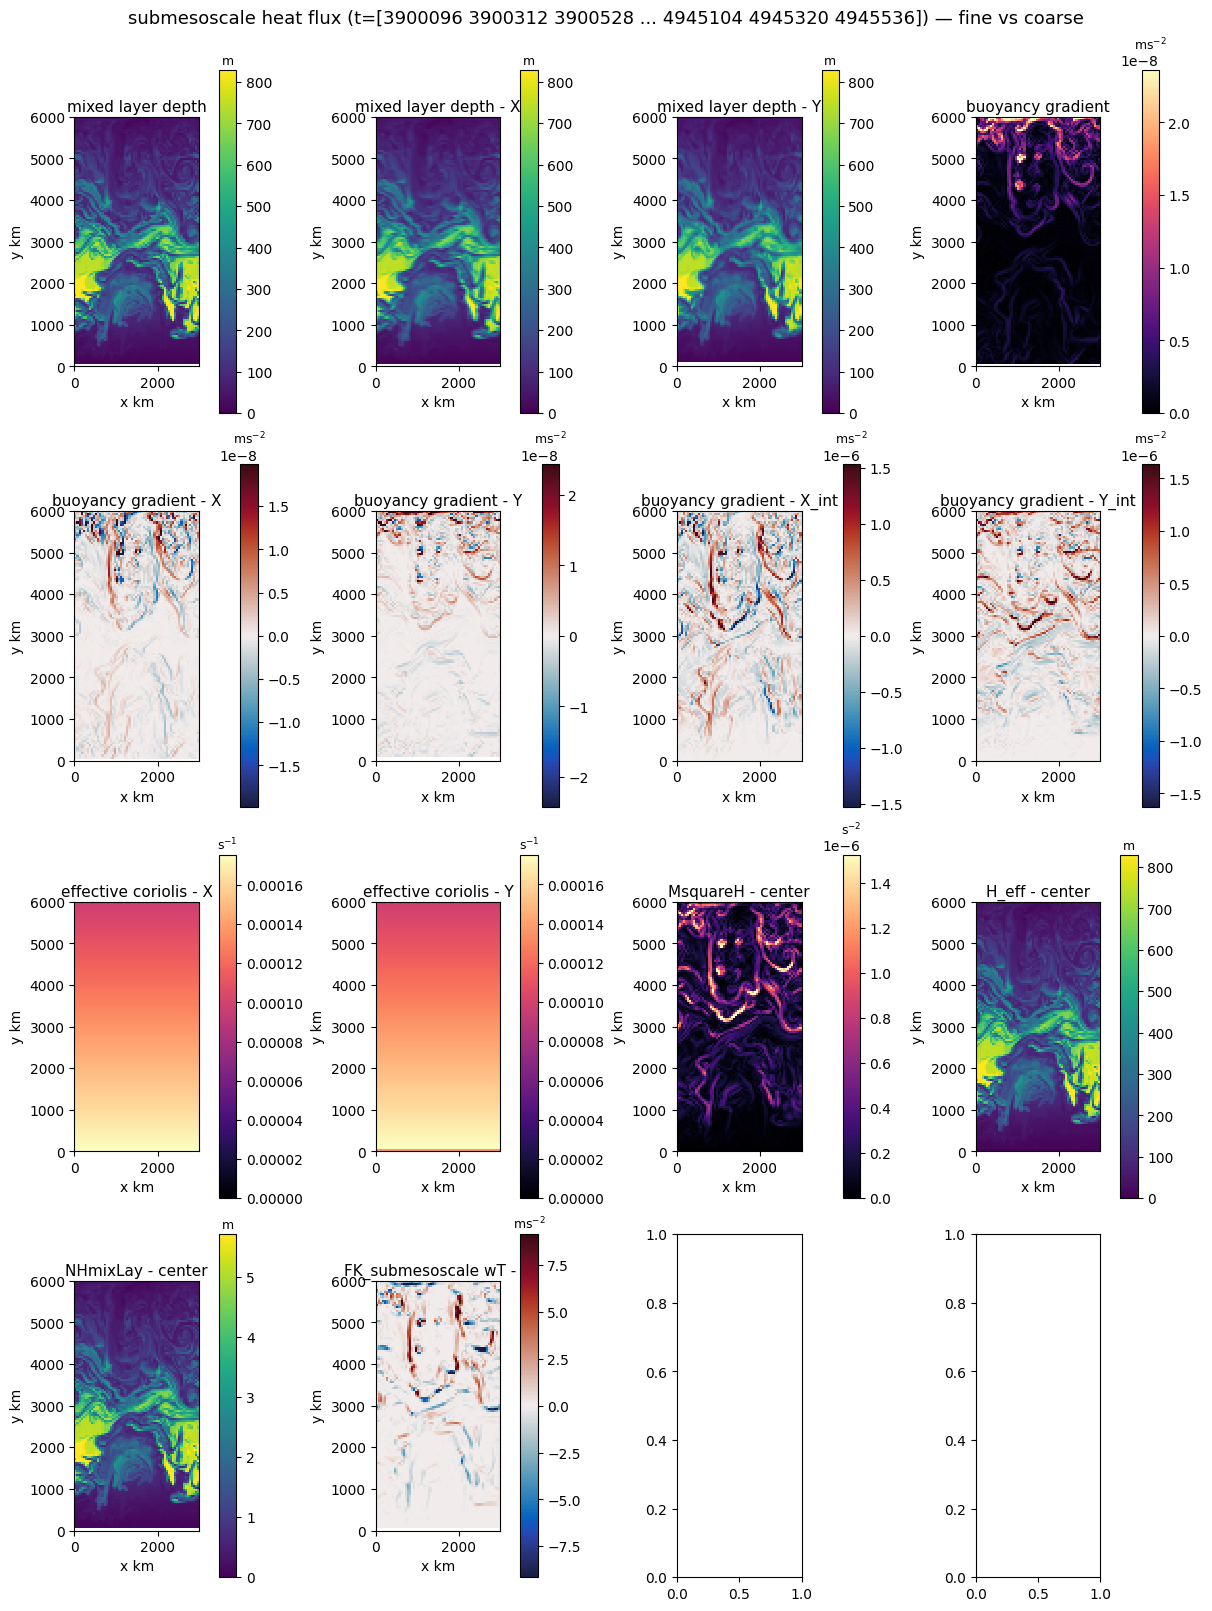

In [28]:
import sys
from pathlib import Path
sys.path.append(str(Path.cwd().parent))
import coarsen_UVWTS
import read_mitgcm
import build_coarse_grid
import numpy as np
from matplotlib import pyplot as plt
import cmocean.cm as cmo
from matplotlib.colors import TwoSlopeNorm
from matplotlib.colors import Normalize
import wT
import xarray as xr
from MITgcmutils import mds
import mld_avg
import importlib
importlib.reload(wT)   # force reload
importlib.reload(read_mitgcm) 
importlib.reload(build_coarse_grid) 
#  MITgcm path
path_scratch = '/scratch/jczhang/'
path_MITgcm = 'MITgcm_5km/MITgcm/verification/tutorial_reentrant_channel/run/'
grid_dir = path_scratch + path_MITgcm
# time index
nStep1, nStep2, dS = 3900096, 4945536, 216
time_index = np.arange(nStep1, nStep2 + 1, dS, dtype=int)
num_data = time_index.size
print("Total data number is:", num_data)
# choose a vertical level
k = 0
box_i, box_j=10, 10
# get the grid variables and create the ds
ds_fine = read_mitgcm.read_mitgrid_staggered(grid_dir)
ds_coarse = build_coarse_grid.build_coarse_grid_staggered(ds_fine,box_j=box_j, box_i=box_i)

# coordinate variable
XC = ds_fine["XC"].values
YC = ds_fine["YC"].values
XCc = ds_coarse["XC"].values
YCc = ds_coarse["YC"].values

# limits function
def sym_limits(Z, q = 0.995):
    v = np.nanquantile(np.abs(Z), q)
    return float(v)

def pos_limits(Z, q=0.995):
    v = np.nanquantile(Z, q)
    return float(v)

# load the data
# submeso_wT_npy = np.load("./var/submeso_wT.npy")
# print(submeso_wT_npy.shape)

W = read_mitgcm._ocean_var(grid_dir, "W", time_index[-1], ("k_l","j","i"))
W_coarse = coarsen_UVWTS.coarse_field("W", W, ds_fine, box_j, box_i)
T = read_mitgcm._ocean_var(grid_dir, "T", time_index[-1], ("k","j","i"))
T_coarse = coarsen_UVWTS.coarse_field("T", T, ds_fine, box_j, box_i)

ds_ocean = xr.Dataset(dict(W=W, T=T))
ds_ocean_c = xr.Dataset(dict(W=W_coarse, T=T_coarse))

submeso_wT_coarse = wT.submeso_vertical_heat_flux(ds_fine, ds_coarse, ds_ocean, ds_ocean_c, box_j = 10, box_i = 10,boundary_Z = "fill", to_wm2 = True)

#  mixed layer avergae
diagMXL = mds.rdmds(path_scratch + path_MITgcm + 'Diags/' +'DiagMXL_2d', time_index[-1])
kpphbl = xr.DataArray(diagMXL[1, :,:], dims = ("j","i"), name = "kpphbl")
kpphbl_coarse = coarsen_UVWTS.coarse_field("kpphbl", kpphbl, ds_fine, box_j, box_i)
submeso_wT_coarse_mld = mld_avg.mld_avg(submeso_wT_coarse, kpphbl_coarse, ds_coarse)

# div_coarse_mld[2403 + _ ,:,:]
fields = {
    "mixed layer depth":  {"Z": kpphbl_coarse[:,:],    "units": r"m",    "kind": "positive", "cmap": plt.cm.viridis, "X": XCc/1e3, "Y": YCc/1e3 },
    "mixed layer depth - X":  {"Z": mixLayerU[:,:],    "units": r"m",    "kind": "positive", "cmap": plt.cm.viridis, "X": XCc/1e3, "Y": YCc/1e3 },
    "mixed layer depth - Y":  {"Z": mixLayerV[:,:],    "units": r"m",    "kind": "positive", "cmap": plt.cm.viridis, "X": XCc/1e3, "Y": YCc/1e3 },
    "buoyancy gradient":  {"Z": b_grad[k,:,:],         "units": r"ms$^{-2}$",    "kind": "positive", "cmap": plt.cm.magma, "X": XCc/1e3, "Y": YCc/1e3 },
    "buoyancy gradient - X":  {"Z": dBdx_u[k,:,:],         "units": r"ms$^{-2}$",    "kind": "signed", "cmap": cmo.balance, "X": XCc/1e3, "Y": YCc/1e3 },
    "buoyancy gradient - Y":  {"Z": dBdy_v[k,:,:],         "units": r"ms$^{-2}$",    "kind": "signed", "cmap": cmo.balance, "X": XCc/1e3, "Y": YCc/1e3 },
    "buoyancy gradient - X_int":  {"Z": dBuoyX_Hu_int[:,:],         "units": r"ms$^{-2}$",    "kind": "signed", "cmap": cmo.balance, "X": XCc/1e3, "Y": YCc/1e3 },
    "buoyancy gradient - Y_int":  {"Z": dBuoyY_Hv_int[:,:],         "units": r"ms$^{-2}$",    "kind": "signed", "cmap": cmo.balance, "X": XCc/1e3, "Y": YCc/1e3 },
    "effective coriolis - X":  {"Z": f_U[:,:],         "units": r"s$^{-1}$",    "kind": "positive", "cmap": plt.cm.magma, "X": XCc/1e3, "Y": YCc/1e3 },
    "effective coriolis - Y":  {"Z": f_V[:,:],         "units": r"s$^{-1}$",    "kind": "positive", "cmap": plt.cm.magma, "X": XCc/1e3, "Y": YCc/1e3 },
    "MsquareH - center":  {"Z": MsquareH[:,:],         "units": r"s$^{-2}$",    "kind": "positive", "cmap": plt.cm.magma, "X": XCc/1e3, "Y": YCc/1e3 },
    "H_eff - center":  {"Z": H_eff[:,:],         "units": r"m",    "kind": "positive", "cmap": plt.cm.viridis, "X": XCc/1e3, "Y": YCc/1e3 },
    "NHmixLay - center":  {"Z": NHmixLay[:,:],         "units": r"m",    "kind": "positive", "cmap": plt.cm.viridis, "X": XCc/1e3, "Y": YCc/1e3 },
    "FK_submesoscale wT - X":  {"Z": submeso_wT_FK[:,:],         "units": r"ms$^{-2}$",    "kind": "signed", "cmap": cmo.balance, "X": XCc/1e3, "Y": YCc/1e3 },
    # "submeso_wT coarse":  {"Z": submeso_wT_coarse[k,:,:],    "units": r"m s$^{-1}$",    "kind": "signed", "cmap": cmo.balance, "X": XCc[:,:]/1e3, "Y": YCc[:,:]/1e3},
    # "submeso_wT coarse mld":  {"Z": submeso_wT_coarse_mld[:,:],  "units": r"m s$^{-1}$", "kind": "signed", "cmap": cmo.balance, "X": XCc/1e3, "Y": YCc/1e3},
    # "submeso_wT coarse mld Fox Kemper":  {"Z": submeso_wT_FK[:,:],  "units": r"m s$^{-1}$", "kind": "signed", "cmap": cmo.balance, "X": XCc/1e3, "Y": YCc/1e3},

}

# Compute norms/limits per field
for key, meta in fields.items():    # key is the variable name, meta is the dict contains the variables, units...
    Z = meta["Z"]
    if meta["kind"] == "signed":
        q = sym_limits(Z)
        meta["norm"] = TwoSlopeNorm(vcenter=0.0, vmin=-q, vmax=+q)
    elif meta["kind"] == "positive":
        q = pos_limits(Z)
        meta["norm"] = Normalize(vmin=0.0, vmax=q)
    elif meta["kind"] == "seq":
        meta["norm"] = Normalize(vmin=np.nanmin(Z), vmax=np.nanmax(Z))
    else:
        meta["norm"] = None

# Plot: 2×5
fig, axes = plt.subplots(4, 4, figsize=(12, 16), constrained_layout=True, squeeze=False)
axes = axes.ravel()

for ax, (title, meta) in zip(axes, fields.items()):
    X = meta["X"]; Y = meta["Y"]; Z = meta["Z"]; 
    cmap = meta["cmap"]
    norm = meta["norm"]
    pc = ax.pcolormesh(X, Y, Z, shading='auto', cmap=cmap, norm=norm)
    ax.set_aspect('equal', adjustable='box')
    ax.set_title(title, fontsize=11, pad=4)
    ax.set_xlabel('x km'); ax.set_ylabel('y km')
    cb = fig.colorbar(pc, ax=ax, pad=0.02)
    cb.ax.set_title(meta["units"], pad=4, fontsize=9)

fig.suptitle(f"submesoscale heat flux (t={time_index}) — fine vs coarse", fontsize=13)


# R2

In [8]:
import numpy as np

def r2_global(y_true, y_pred):
    """
    Global R² over all samples and pixels.
    y_true, y_pred: np.ndarray with same shape (N, H, W) or (N, 1, H, W)
    """
    y_true = np.asarray(y_true)
    y_pred = np.asarray(y_pred)

    # remove singleton channel if present
    if y_true.ndim == 4 and y_true.shape[1] == 1:
        y_true = y_true[:, 0, ...]
        y_pred = y_pred[:, 0, ...]
    
    # mask NaNs (e.g. land)
    mask = np.isfinite(y_true) & np.isfinite(y_pred)
    y_true_flat = y_true[mask]
    y_pred_flat = y_pred[mask]

    # standard R² = 1 - SSR / SST
    ss_res = np.sum((y_true_flat - y_pred_flat)**2)
    ss_tot = np.sum((y_true_flat - y_true_flat.mean())**2)

    return 1.0 - ss_res / ss_tot


def r2_per_image(y_true, y_pred):
    """
    R² for each image separately, plus their mean.
    Returns: r2_list (N,), r2_mean (scalar)
    """
    y_true = np.asarray(y_true)
    y_pred = np.asarray(y_pred)

    if y_true.ndim == 4 and y_true.shape[1] == 1:
        y_true = y_true[:, 0, ...]
        y_pred = y_pred[:, 0, ...]

    N = y_true.shape[0]
    r2_list = np.empty(N, dtype=float)

    for n in range(N):
        yt = y_true[n]
        yp = y_pred[n]

        mask = np.isfinite(yt) & np.isfinite(yp)
        yt_flat = yt[mask]
        yp_flat = yp[mask]

        ss_res = np.sum((yt_flat - yp_flat)**2)
        ss_tot = np.sum((yt_flat - yt_flat.mean())**2)

        r2_list[n] = 1.0 - ss_res / ss_tot

    return r2_list, float(r2_list.mean())

In [25]:
data = np.load("/scratch/jczhang/data_5km/var_6000/submeso_wT.npz")
y_true = data["data"][0:9,]
print(y_true.shape)

(9, 116, 58)


In [18]:
def _fit_z_norm_y(y_train):
    """
    y_train: (N, 1, H, W) or (N, H, W) or (N,)
    Returns scalar mu, sd (broadcastable).
    """
    EPS = 1e-12
    mu = y_train.mean()
    sd = y_train.std(ddof=1) + EPS
    return np.float32(mu), np.float32(sd)

def _apply_z_norm_y(y, mu, sd):
    return (y - mu) / sd
    
y_mu, y_sd = _fit_z_norm_y(y_true)
y_true = _apply_z_norm_y(y_true, y_mu, y_sd)

data_arr_mu, data_arr_sd = _fit_z_norm_y(data_arr)
data_arr = _apply_z_norm_y(data_arr, data_arr_mu, data_arr_sd)

In [13]:
R2_fk_global = r2_global(y_true, data_arr)

-0.9462417244687131


In [33]:
print(R2_fk_global)

-0.01614192723942498
